In [6]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

In [8]:

!wget -q "https://archive.ics.uci.edu/static/public/352/online+retail.zip" -O online_retail.zip

import zipfile
import pandas as pd

with zipfile.ZipFile("online_retail.zip", "r") as z:
    z.extractall("/content")

df = pd.read_excel("/content/Online Retail.xlsx")

print("DATASET LOADED SUCCESSFULLY!")
print(df.head())
print("Dataset Shape:", df.shape)


DATASET LOADED SUCCESSFULLY!
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
Dataset Shape: (541909, 8)


In [9]:
# Data Cleaning
df = df.dropna(subset=['CustomerID'])
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]
df = df.drop_duplicates()

df['CustomerID'] = df['CustomerID'].astype(int)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)
print(df.head())

Data Cleaning Completed!
Cleaned Dataset Shape: (392692, 9)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  
0 2010-12-01 08:26:00       2.55       17850  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75       17850  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  


In [10]:
# RFM Analysis

import pandas as pd

snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print("RFM Analysis Completed!")
print(rfm.head())
print("\nRFM Dataset Shape:", rfm.shape)

RFM Analysis Completed!
            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             2          7   4310.00
12348            75          4   1797.24
12349            19          1   1757.55
12350           310          1    334.40

RFM Dataset Shape: (4338, 3)


In [11]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

print("Feature Scaling Completed!")
print("Scaled Data Shape:", rfm_scaled.shape)
print(rfm_scaled[:5])

Feature Scaling Completed!
Scaled Data Shape: (4338, 3)
[[ 2.33457414 -0.4250965   8.36301037]
 [-0.90534032  0.3544168   0.2516989 ]
 [-0.17535959 -0.03533985 -0.02798783]
 [-0.73534481 -0.4250965  -0.03240559]
 [ 2.17457836 -0.4250965  -0.19081155]]


In [12]:
# K-Means Clustering

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")
print(rfm.head(10))

print("\nCustomers in Each Cluster:")
print(rfm['Cluster'].value_counts())

K-Means Clustering Completed!
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346           326          1  77183.60        3
12347             2          7   4310.00        0
12348            75          4   1797.24        0
12349            19          1   1757.55        0
12350           310          1    334.40        1
12352            36          8   2506.04        0
12353           204          1     89.00        1
12354           232          1   1079.40        1
12355           214          1    459.40        1
12356            23          3   2811.43        0

Customers in Each Cluster:
Cluster
0    3054
1    1067
3     204
2      13
Name: count, dtype: int64


In [13]:
# Customer Segment Analysis

segment_profiles = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
})

segment_profiles = segment_profiles.rename(
    columns={'Cluster': 'Customer_Count'}
)

print("CUSTOMER SEGMENT PROFILES")
print(segment_profiles.round(2))

CUSTOMER SEGMENT PROFILES
         Recency  Frequency   Monetary  Customer_Count
Cluster                                               
0          43.70       3.68    1353.63            3054
1         248.08       1.55     478.85            1067
2           7.38      82.54  127187.96              13
3          15.50      22.33   12690.50             204


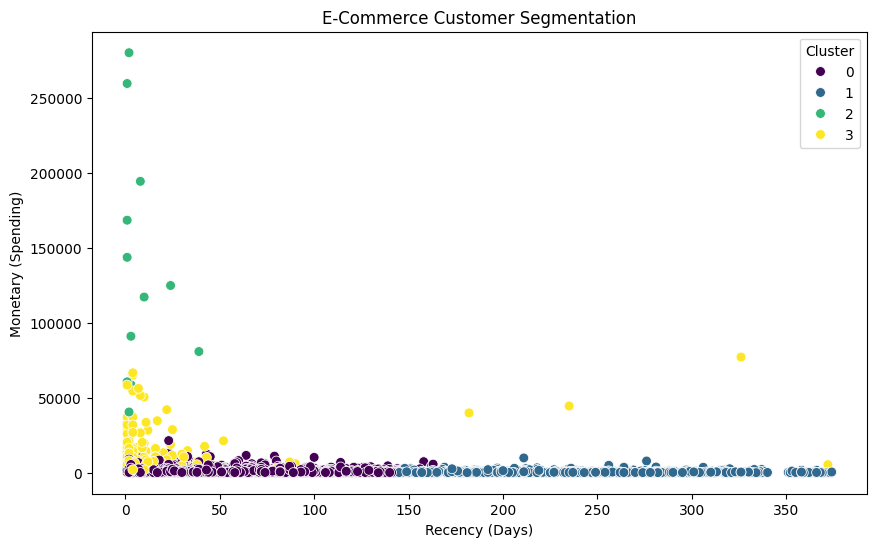

Visualization Completed!


In [14]:
# Customer Segmentation Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('E-Commerce Customer Segmentation')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (Spending)')
plt.savefig('customer_segments.png')
plt.show()

print("Visualization Completed!")

In [15]:
# Product Recommendation System

from sklearn.metrics.pairwise import cosine_similarity

product_data = df.pivot_table(
    index='CustomerID',
    columns='Description',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

product_similarity = cosine_similarity(product_data.T)

product_similarity_df = pd.DataFrame(
    product_similarity,
    index=product_data.columns,
    columns=product_data.columns
)

def recommend_products(product_name, top_n=5):
    if product_name not in product_similarity_df.columns:
        return "Product not found!"

    recommendations = product_similarity_df[product_name].sort_values(
        ascending=False
    ).iloc[1:top_n+1]

    return recommendations

print("Product Recommendation System Ready!")

print(recommend_products(product_data.columns[0]))

Product Recommendation System Ready!
Description
4 PINK DINNER CANDLE SILVER FLOCK     0.664601
PINK/FLOWER RABBIT EGG WARMER         0.402744
4 BLUE DINNER CANDLES SILVER FLOCK    0.362492
GREEN WIRE STANDING CANDLE HOLDER     0.341820
12 IVORY ROSE PEG PLACE SETTINGS      0.313089
Name:  4 PURPLE FLOCK DINNER CANDLES, dtype: float64


In [16]:
# Save Final Project Files

rfm.to_csv('customer_segments.csv')

segment_profiles.to_csv('segment_profiles.csv')

product_similarity_df.to_csv('product_similarity.csv')

print("PROJECT COMPLETED SUCCESSFULLY!")
print("1. customer_segments.csv")
print("2. segment_profiles.csv")
print("3. product_similarity.csv")
print("4. customer_segments.png")

PROJECT COMPLETED SUCCESSFULLY!
1. customer_segments.csv
2. segment_profiles.csv
3. product_similarity.csv
4. customer_segments.png


In [17]:
from google.colab import files

files.download('customer_segments.csv')
files.download('segment_profiles.csv')
files.download('product_similarity.csv')
files.download('customer_segments.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>